Rows: 9800
Columns: 18
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales']


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   object 
 2   Order Date     9800 non-null   object 
 3   Ship Date      9800 non-null   object 
 4   Ship Mode      9800 non-null   object 
 5   Customer ID    9800 non-null   object 
 6   Customer Name  9800 non-null   object 
 7   Segment        9800 non-null   object 
 8   Country        9800 non-null   object 
 9   City           9800 non-null   object 
 10  State          9800 non-null   object 
 11  Postal Code    9789 non-null   float64
 12  Region         9800 non-null   object 
 13  Product ID     9800 non-null   object 
 14  Category       9800 non-null   object 
 15  Sub-Category   9800 non-null   object 
 16  Product Name   9800 non-null   object 
 17  Sales          9800 non-null   float64
dtypes: float

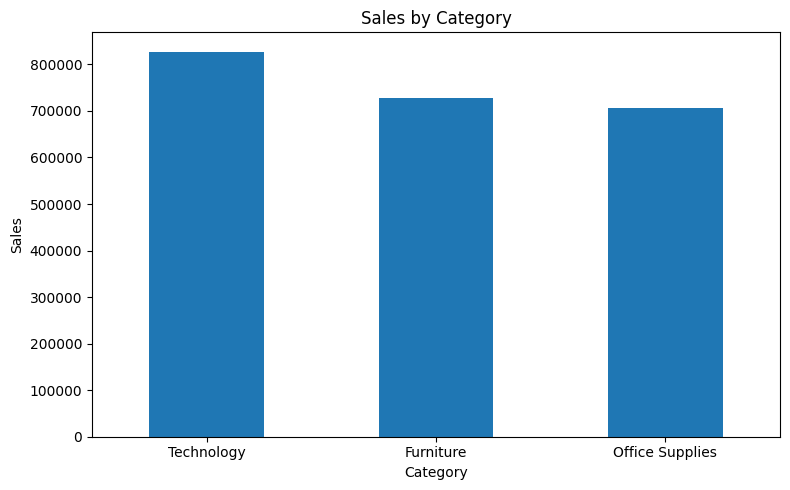

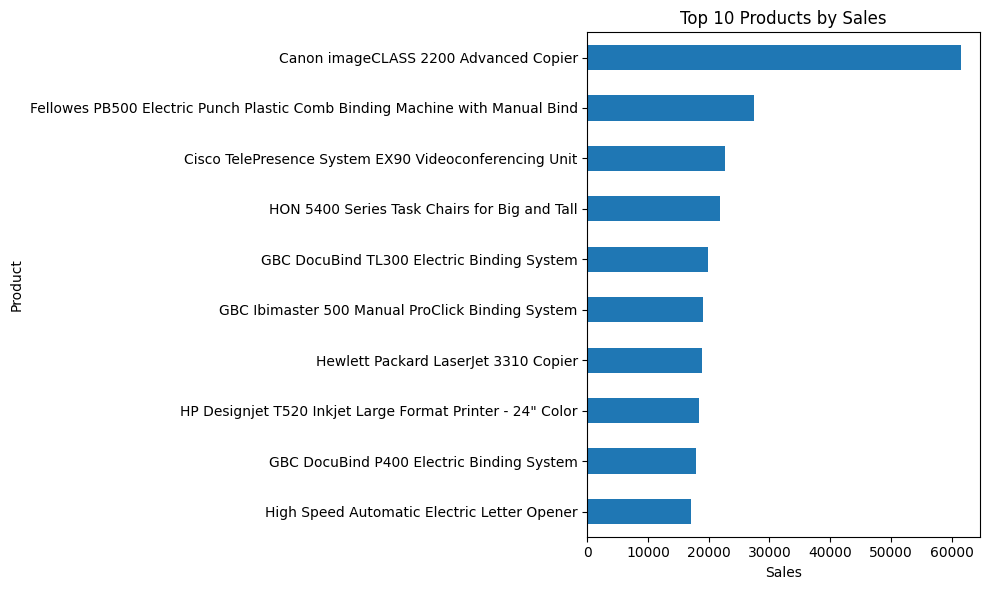

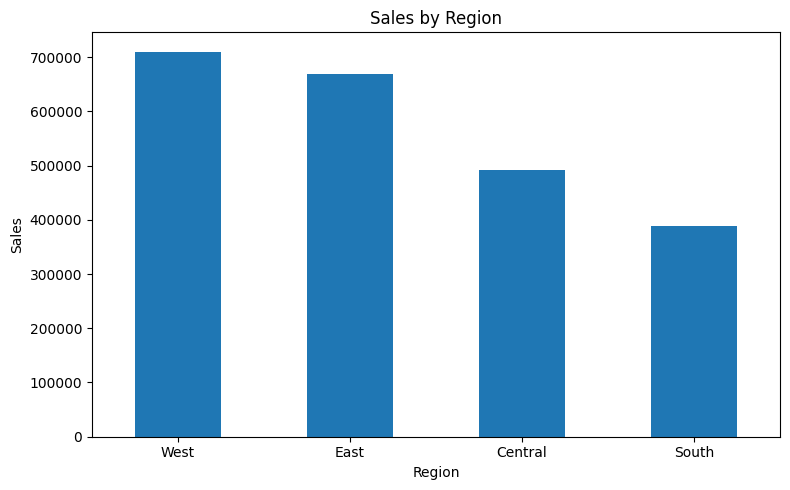

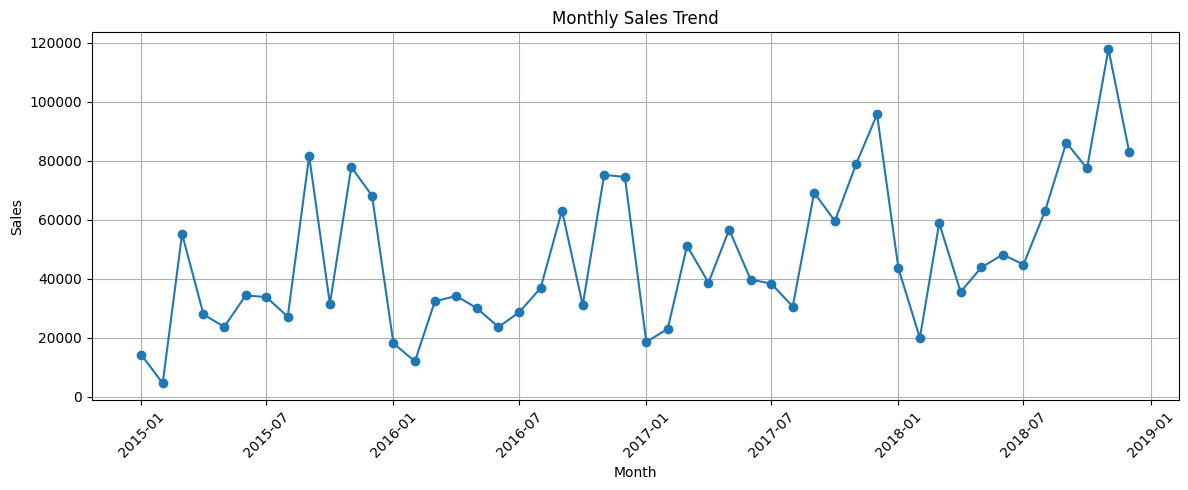

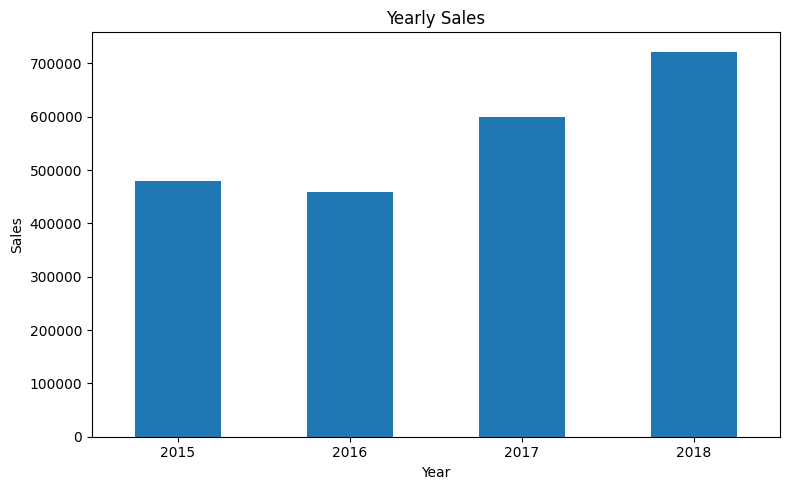

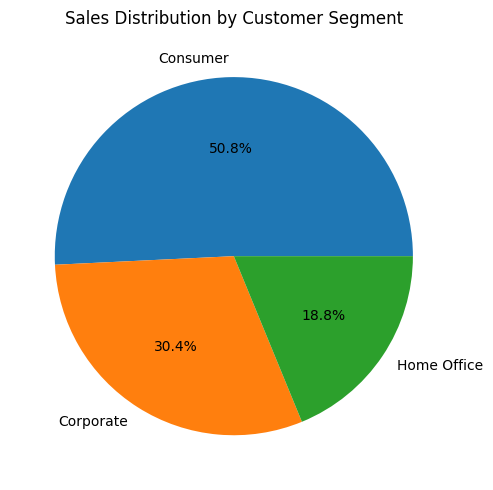

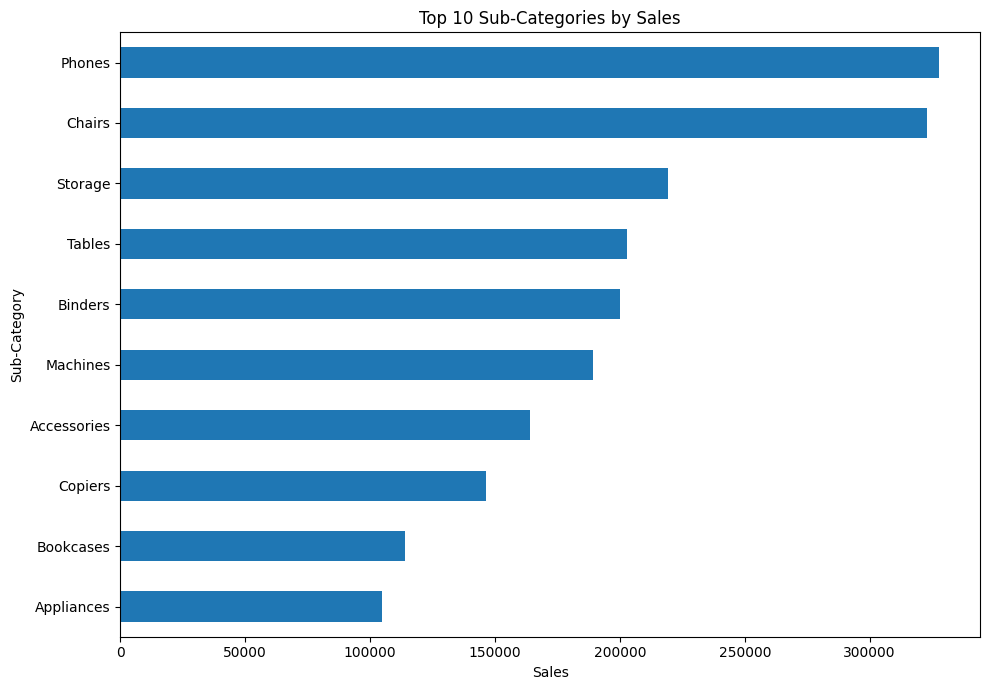

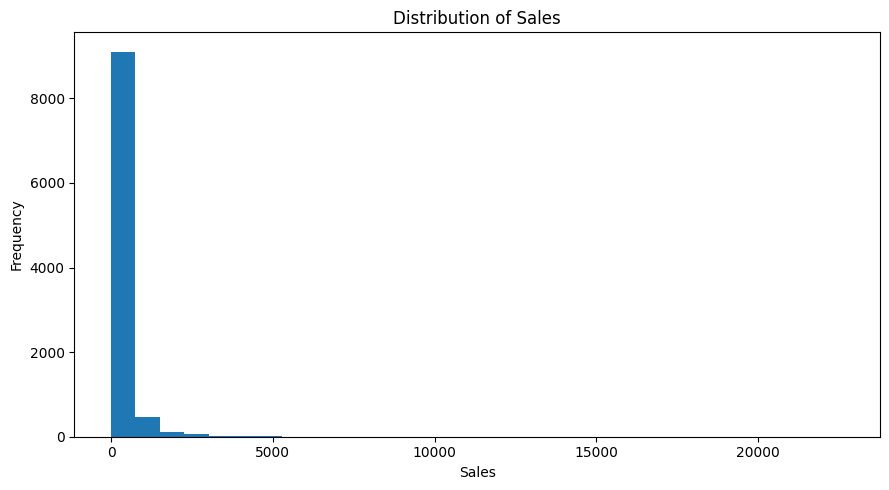

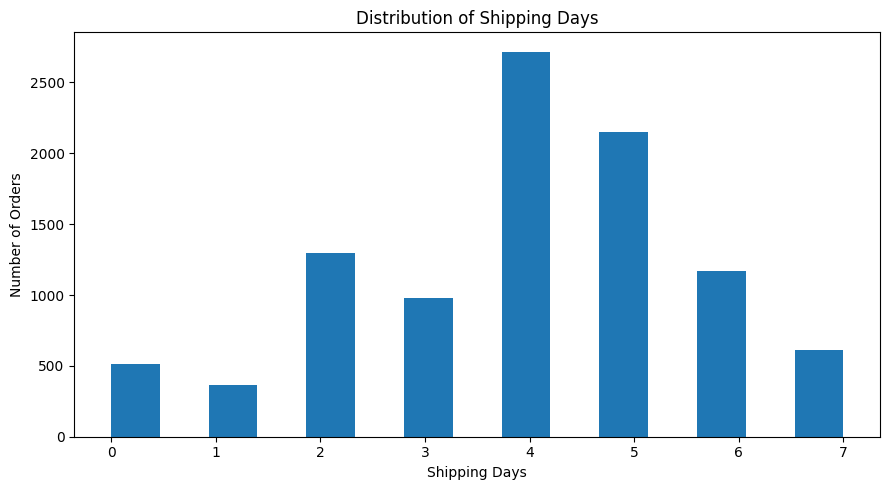

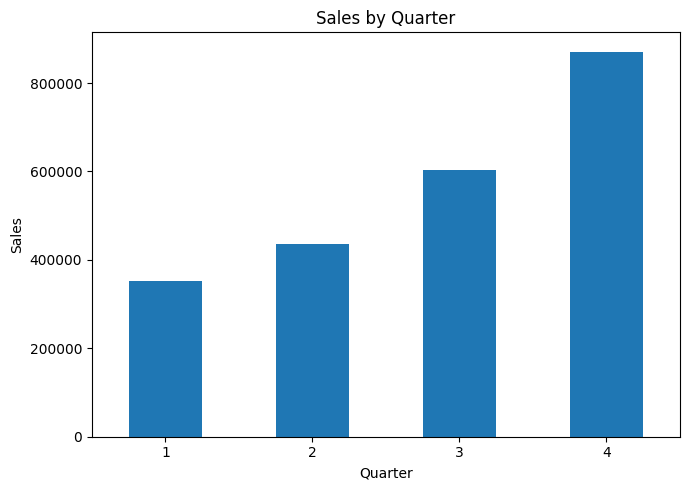


Best Category: Technology
Best Region: West
Best Customer Segment: Consumer
Top Product: Canon imageCLASS 2200 Advanced Copier
Best Sales Year: 2018

Cleaned dataset saved successfully.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../Dataset/superstore.csv")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print(df.columns.tolist())
display(df.head())

df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()

df["Order Date"] = pd.to_datetime(df["Order Date"], dayfirst=True, errors="coerce")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], dayfirst=True, errors="coerce")

df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Month_Name"] = df["Order Date"].dt.month_name()
df["Quarter"] = df["Order Date"].dt.quarter
df["Shipping_Days"] = (df["Ship Date"] - df["Order Date"]).dt.days
df["Order_Month"] = df["Order Date"].dt.to_period("M").dt.to_timestamp()

total_sales = df["Sales"].sum()
total_orders = df["Order ID"].nunique()
total_customers = df["Customer ID"].nunique()
total_products = df["Product ID"].nunique()
average_order_value = total_sales / total_orders
average_sales_per_customer = total_sales / total_customers
average_shipping_days = df["Shipping_Days"].mean()

print("\nTotal Sales:", round(total_sales, 2))
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
print("Total Products:", total_products)
print("Average Order Value:", round(average_order_value, 2))
print("Average Sales per Customer:", round(average_sales_per_customer, 2))
print("Average Shipping Days:", round(average_shipping_days, 2))

print("\nMean Sales:", round(df["Sales"].mean(), 2))
print("Median Sales:", round(df["Sales"].median(), 2))
print("Mode Sales:", round(df["Sales"].mode()[0], 2))
print("Variance:", round(df["Sales"].var(), 2))
print("Standard Deviation:", round(df["Sales"].std(), 2))
print("Minimum Sales:", round(df["Sales"].min(), 2))
print("Maximum Sales:", round(df["Sales"].max(), 2))
print("Sales Range:", round(df["Sales"].max() - df["Sales"].min(), 2))

yearly_sales = df.groupby("Year")["Sales"].sum().sort_index()
monthly_sales = df.groupby("Order_Month")["Sales"].sum().sort_index()
category_sales = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)
subcategory_sales = df.groupby("Sub-Category")["Sales"].sum().sort_values(ascending=False)
product_sales = df.groupby("Product Name")["Sales"].sum().sort_values(ascending=False)
region_sales = df.groupby("Region")["Sales"].sum().sort_values(ascending=False)
state_sales = df.groupby("State")["Sales"].sum().sort_values(ascending=False)
customer_sales = df.groupby(["Customer ID", "Customer Name"])["Sales"].sum().sort_values(ascending=False)
customer_orders = df.groupby(["Customer ID", "Customer Name"])["Order ID"].nunique().sort_values(ascending=False)
segment_sales = df.groupby("Segment")["Sales"].sum().sort_values(ascending=False)
ship_mode_sales = df.groupby("Ship Mode")["Sales"].sum().sort_values(ascending=False)
shipping_by_mode = df.groupby("Ship Mode")["Shipping_Days"].mean().sort_values()
quarter_sales = df.groupby("Quarter")["Sales"].sum().sort_index()

print("\nSales by Year:")
print(yearly_sales)

print("\nSales by Category:")
print(category_sales)

print("\nSales by Sub-Category:")
print(subcategory_sales)

print("\nTop 10 Products:")
print(product_sales.head(10))

print("\nSales by Region:")
print(region_sales)

print("\nTop 10 States:")
print(state_sales.head(10))

print("\nTop 10 Customers:")
print(customer_sales.head(10))

print("\nTop Customers by Number of Orders:")
print(customer_orders.head(10))

print("\nSales by Segment:")
print(segment_sales)

print("\nSales by Ship Mode:")
print(ship_mode_sales)

print("\nAverage Shipping Days by Ship Mode:")
print(shipping_by_mode)

print("\nSales by Quarter:")
print(quarter_sales)

plt.figure(figsize=(8,5))
category_sales.plot(kind="bar")
plt.title("Sales by Category")
plt.xlabel("Category")
plt.ylabel("Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10,6))
product_sales.head(10).sort_values().plot(kind="barh")
plt.title("Top 10 Products by Sales")
plt.xlabel("Sales")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8,5))
region_sales.plot(kind="bar")
plt.title("Sales by Region")
plt.xlabel("Region")
plt.ylabel("Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12,5))
plt.plot(monthly_sales.index, monthly_sales.values, marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8,5))
yearly_sales.plot(kind="bar")
plt.title("Yearly Sales")
plt.xlabel("Year")
plt.ylabel("Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7,5))
segment_sales.plot(kind="pie", autopct="%1.1f%%")
plt.title("Sales Distribution by Customer Segment")
plt.ylabel("")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10,7))
subcategory_sales.head(10).sort_values().plot(kind="barh")
plt.title("Top 10 Sub-Categories by Sales")
plt.xlabel("Sales")
plt.ylabel("Sub-Category")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9,5))
plt.hist(df["Sales"], bins=30)
plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9,5))
plt.hist(df["Shipping_Days"].dropna(), bins=15)
plt.title("Distribution of Shipping Days")
plt.xlabel("Shipping Days")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7,5))
quarter_sales.plot(kind="bar")
plt.title("Sales by Quarter")
plt.xlabel("Quarter")
plt.ylabel("Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("\nBest Category:", category_sales.idxmax())
print("Best Region:", region_sales.idxmax())
print("Best Customer Segment:", segment_sales.idxmax())
print("Top Product:", product_sales.idxmax())
print("Best Sales Year:", yearly_sales.idxmax())

df.to_csv("../Dataset/cleaned_superstore.csv", index=False)

print("\nCleaned dataset saved successfully.")

